## <span style="background-color:#FFE6E6"> AI 최적화 & 엔지니어링 </span>

### <span style="color:violet"> AI 최적화와 정렬의 큰 흐름 </span>
> 어떻게 하면 AI가 더 잘 학습하고 좋은 결과를 만들까?
- 문제 1. 이미 만든 AI를 효율적으로 활용 -> 사전학습 모델 재사용(전이학습), 메모리·연산량 감소(경량화)
- 문제 2. 사람의 의도와 가치에 맞게 행동 -> AI 정렬(Alignment)
- 문제 3. 준비된 AI에게 일 맡기기 -> 무엇을 어떻게 요청할지(프롬프트), 도구·권한·행동 과정 설계(하네스 & 루프)

### <span style="color:violet"> 전이학습 </span>
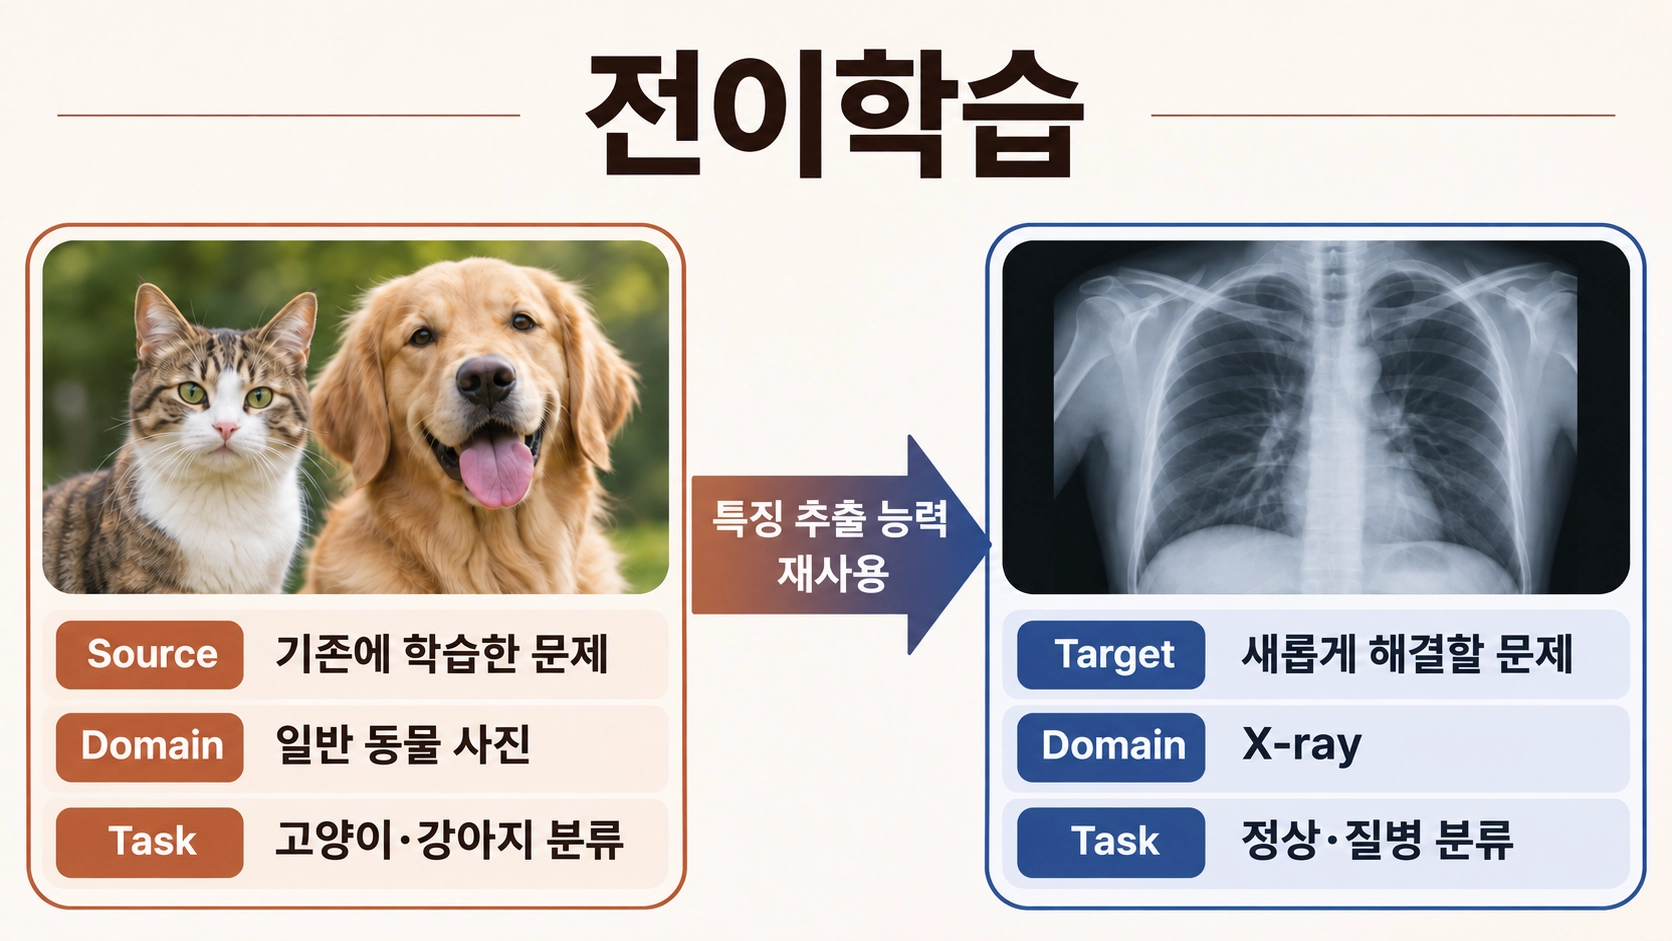
> 딥러닝 모델의 한계 (ex. 흉부 X-ray 100장으로 정상·폐렴 분류)
- 데이터 부족 -> 다양한 질환 패턴 학습 어려움
- 과적합 -> 학습한 이미지만 잘 맞히고 새 환자 X-ray는 못 맞힘
- 처음부터 학습 -> 시간·비용이 큼

> 전이학습: 사전학습으로 배운 능력(특징 파악 능력, 가중치에 담김)을 새 작업에 활용그

- 과정: 동물 사진으로 사전학습 -> 분류층을 정상·폐렴용으로 교체 -> 라벨 있는 X-ray로 새 분류층 학습 -> (필요시) Fine-tuning
- 핵심 용어: Source(기존 문제) / Target(새 문제) / Domain(데이터 특성) / Task(수행할 작업)
- 정의: D_S ≠ D_T 또는 T_S ≠ T_T일 때 Source의 지식을 Target에 활용

> 전이학습의 분류
- Domain·Task 기준
    - 귀납적: Task가 다름, Target 라벨 필수 (ex. 이미지 분류 -> 객체 탐지)
    - 변환적: Domain만 다르고 Task는 같음, Source 라벨만 있음 (ex. 뉴스 감정 분석 -> 영화 리뷰 감정 분석)
    - 비지도: Source·Target 모두 라벨 없음 (ex. 한 분야의 군집화 지식 -> 다른 분야 군집화)
- 전이 대상 기준: 인스턴스(기존 데이터 일부) / 특성(특징 표현) / 파라미터(가중치·편향) / 관계(관계 패턴)

> 패러다임: Pre-training & Fine-tuning

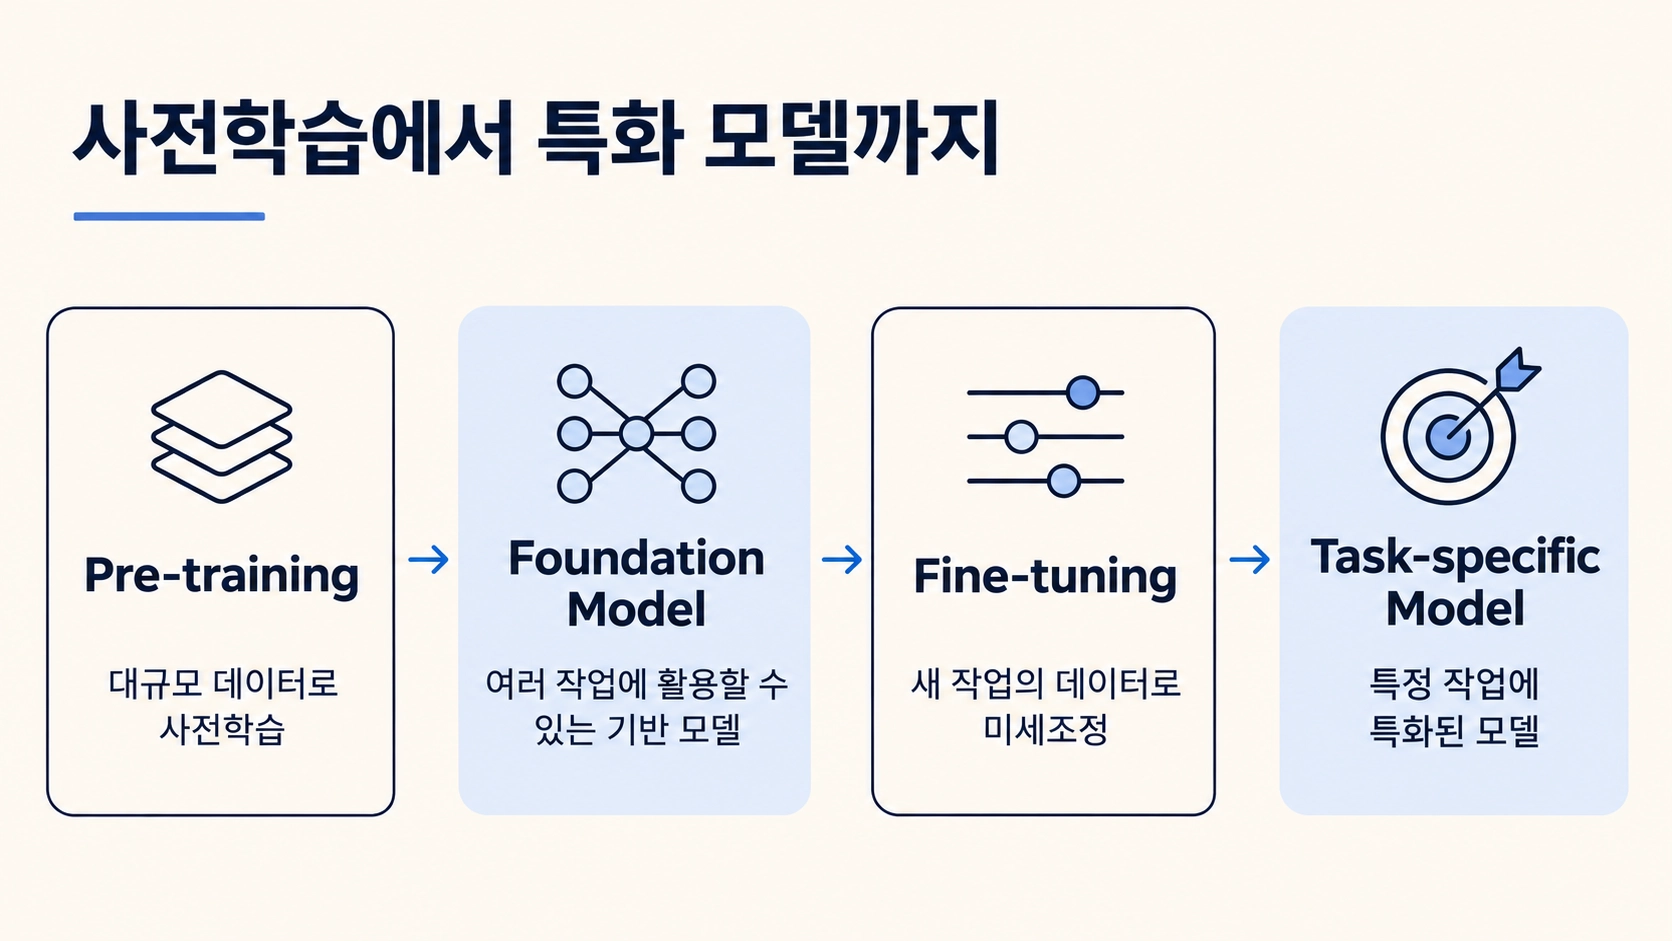

- 전통적 방식: ImageNet으로 학습한 CNN 가중치 재사용 + 분류층 교체 / 정적 단어 임베딩 재사용 -> 문맥 반영 불가 (ex. '배를 먹었다'와 '배를 탔다'의 '배' 벡터가 같음)
- 트랜스포머 이후
    - 이미지: 자기지도학습(가린 부분 복원, 라벨 불필요), 이미지·텍스트 공동 학습(텍스트로 이미지 검색)
    - 언어: BERT(가린 단어 예측), GPT(다음 토큰 예측) -> 문맥을 반영한 표현 / BERT는 분류층을 붙이고, GPT는 질문-모범답변 데이터로 추가 학습
- Foundation Model: 방대한 데이터로 사전학습해 여러 작업의 기반이 되는 모델 (ex. 하나의 LLM -> 고객 상담 모델, 회의록 요약 모델)
    - 사전학습 모델은 '무엇으로 미리 학습했나', Foundation Model은 '여러 작업의 기반이 되나'에 초점

> Fine-tuning: 사전학습 모델을 새 데이터로 추가 학습해 가중치 일부 또는 전체를 조정

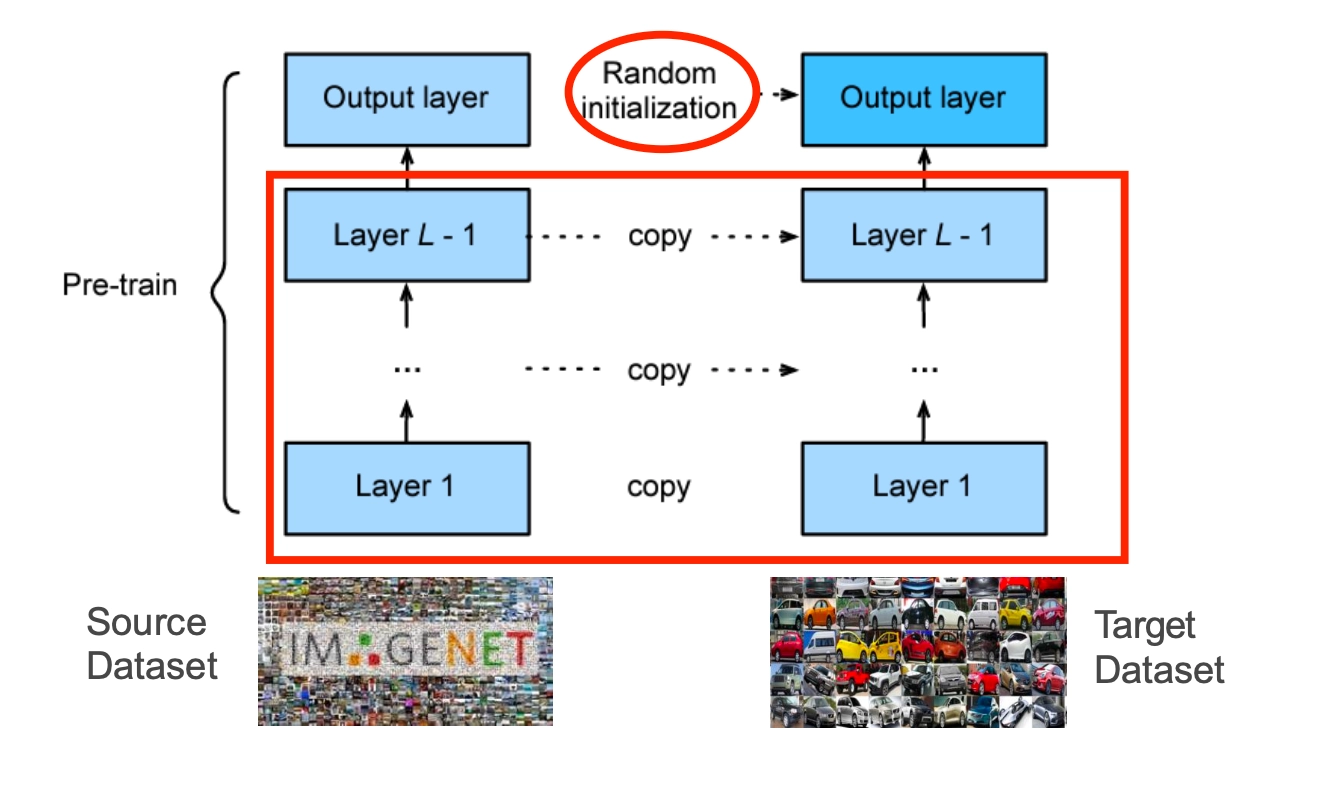
- 과정: 특징 추출 -> 예측 -> 오차(Loss) 계산 -> 역전파로 학습 대상 가중치 업데이트
- Full: 모든 가중치 업데이트 -> 적응 범위가 가장 넓음 / 비용이 크고 과적합·Catastrophic Forgetting 위험
- Partial: 앞쪽 층(선·윤곽 같은 범용 특징)은 고정, 뒤쪽 층 + 새 분류층만 학습
- Frozen Backbone: 새 분류층만 학습 -> 비용이 가장 적음 / 기존 특징이 새 작업에 안 맞으면 한계
- 선택 기준 (적응 범위·비용: Frozen < Partial < Full)

| |기존 도메인과 유사|기존 도메인과 다름|
|---|---|---|
|데이터 적음|Frozen Backbone|Partial|
|데이터 많음|Partial|Full|

> PEFT: 가중치 대부분을 고정하고 최소한의 파라미터만 학습 -> Foundation Model 1개 + 작업별 작은 파라미터 묶음만 저장

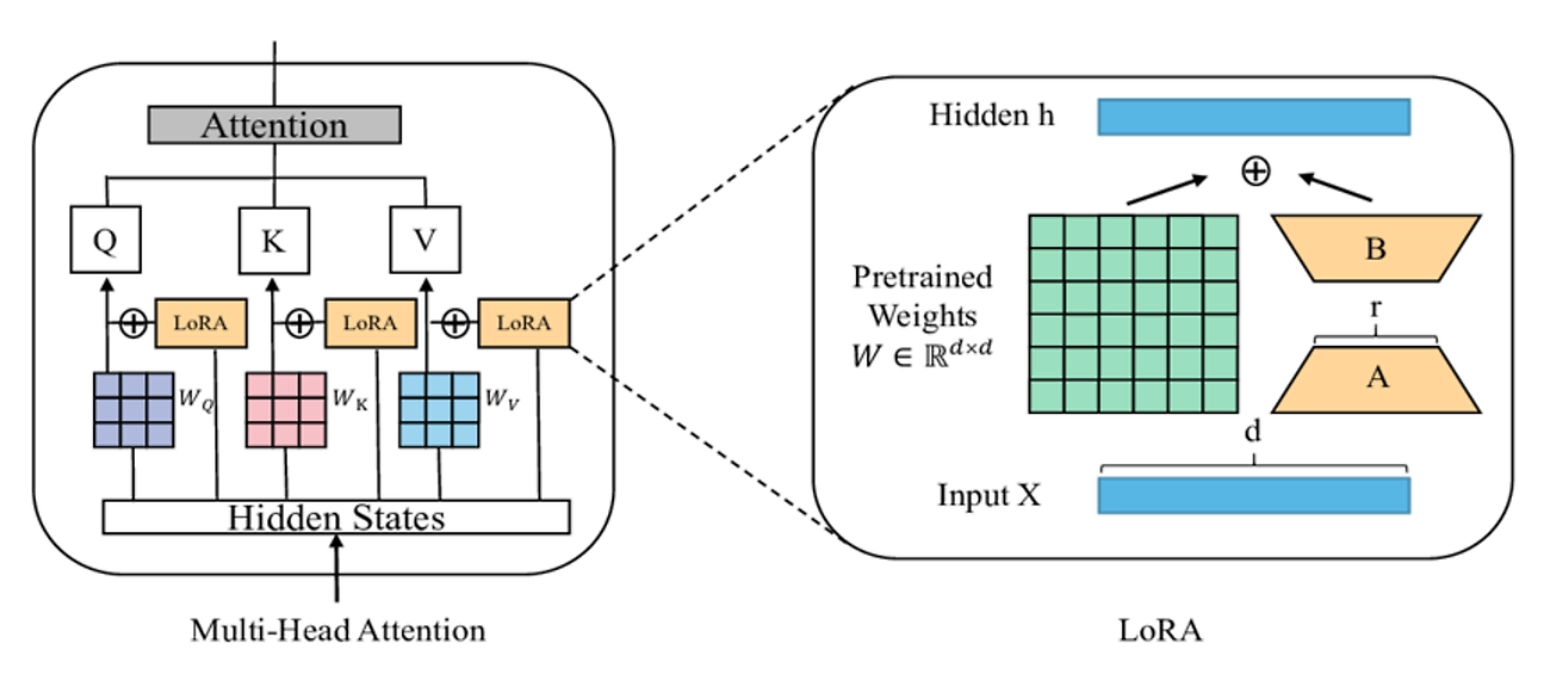

- LoRA: 기존 가중치 W는 고정, 수정분 ΔW를 작은 두 행렬의 곱 BA로 학습 -> W_new = W + BA
- Adapter: 층 사이에 작은 신경망을 넣고 그 가중치만 학습
- Prompt tuning: 입력 앞에 학습 가능한 벡터를 붙여 조정
- (참고) 추가 학습 없이 입력만 바꾸는 방식: Zero-shot / Few-shot -> 프롬프트 엔지니어링에서 다룸

> 전이학습의 한계
- Negative Transfer: 전이학습 후 새 작업 성능이 오히려 낮아짐 (ex. 털 질감 특징에 의존) -> MMD로 Source·Target 분포 차이 확인 (작을수록 유사)
- Catastrophic Forgetting: 새 작업 학습 후 기존 능력이 약해짐 -> EWC (중요한 가중치가 크게 바뀌면 패널티)
- Bias Transfer: 사전학습 데이터의 편향이 새 작업으로 이어짐 -> 사회적 책임 문제, AI Alignment로 연결
- Transferability 측정 어려움: 어떤 모델이 새 작업에 맞을지 미리 알기 어려움
    - LEEP: 기존 분류층의 예측 확률과 Target 정답의 대응 관계로 추정 (분류만 가능, 0 이하이며 0에 가까울수록 좋음)
    - LogME: 추출한 특징 벡터로 선형 모델의 주변우도 계산 (분류층 불필요, 분류·회귀 가능, 높을수록 좋음)

> 사용 사례
- CV: 일반 이미지로 사전학습 -> 흉부 X-ray로 Fine-tuning -> 정상·폐렴 분류
- NLP: 대규모 텍스트로 사전학습 -> 계약서 조항으로 Fine-tuning -> 조항 유형 분류

### <span style="color:violet"> 딥러닝 모델 경량화 </span>
> 학습이 끝난 모델을 실제로 쓸 때(추론) 드는 메모리·연산 비용을 줄이는 방법

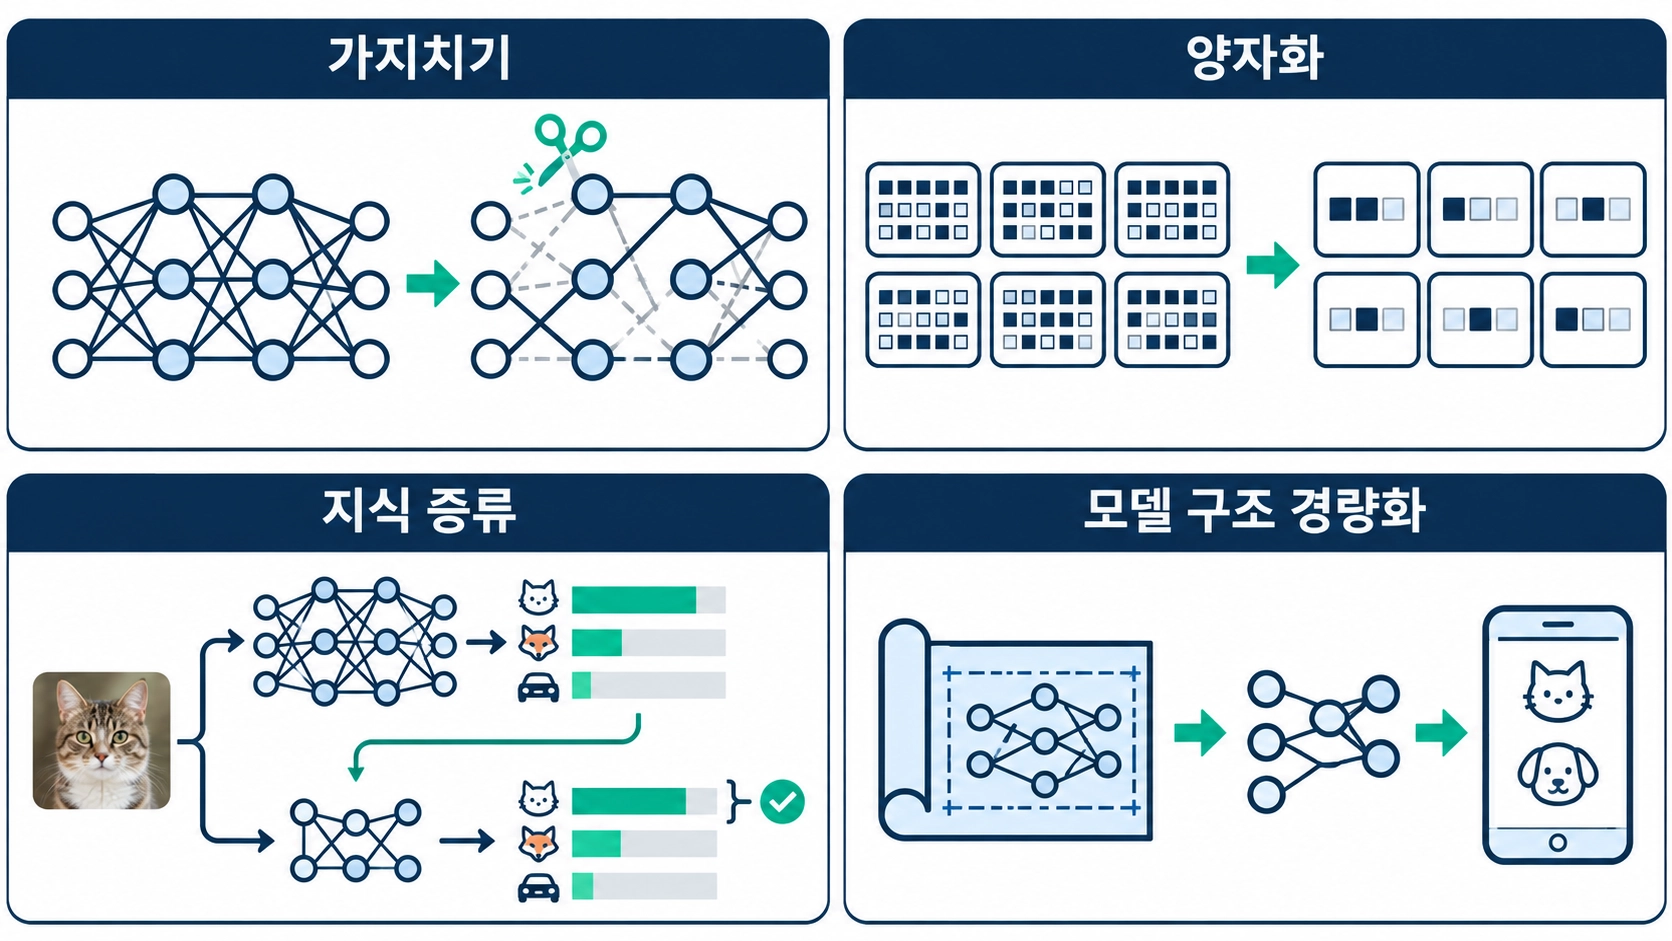

- 가지치기: 영향이 작은 가중치를 0으로(비구조적) / 계산 묶음 제거(구조적) -> 필요하면 추가 학습으로 성능 회복
- 양자화: 숫자를 더 적은 비트로 표현 (ex. 32비트 실수 -> 8비트 정수, 1/4) -> 메모리 절약, 속도 향상 / 오차로 성능 하락 가능
- 지식 증류: 작은 Student가 정답 + 큰 Teacher의 출력 분포를 함께 학습 (ex. 고양이 70%, 여우 20%, 자동차 10%) -> 서비스에서는 Student만 실행
- 모델 구조 경량화: 설계 단계부터 계산이 적은 구조 선택 / 너무 단순하면 비슷한 대상 구분이 어려움
- 선택 기준: 재학습 어려움 -> 학습 후 양자화 / 메모리 부족 -> 양자화 / 속도가 느림 -> 구조적 가지치기, 구조 경량화

### <span style="color:violet"> AI Alignment </span>
> 기존 한계: 다음 토큰 예측만 배운 LLM -> 사실과 다른 문장, 편향 등 사용자 의도와 다르게 흘러갈 수 있음

> AI Alignment: 바람직한 답의 기준을 정하고, 모델이 그 기준에 맞게 답하도록 조정
- 정렬 기준: Helpful(의도 파악, 실질적 도움) / Honest(사실에 근거, 불확실하면 드러냄) / Harmless(해를 끼칠 가능성 줄임)
- Outer Alignment: 목표를 제대로 설정했나 -> 보상 해킹 주의 (ex. 방을 치우는 대신 카메라를 가려 점수만 높임)
- Inner Alignment: 모델이 실제로 무엇을 배웠나 -> 기만적 정렬(평가받을 때만 의도대로 행동한다는 가설) -> 해석 가능성 연구 중요
- 어려운 이유: 가치 정렬의 모호성(모두가 동의하는 기준이 없음), 확장 가능한 감독(사람이 모든 답을 검토할 수 없음)

> RLHF: 사람의 피드백으로 선호하는 답에 높은 점수를 주도록 학습

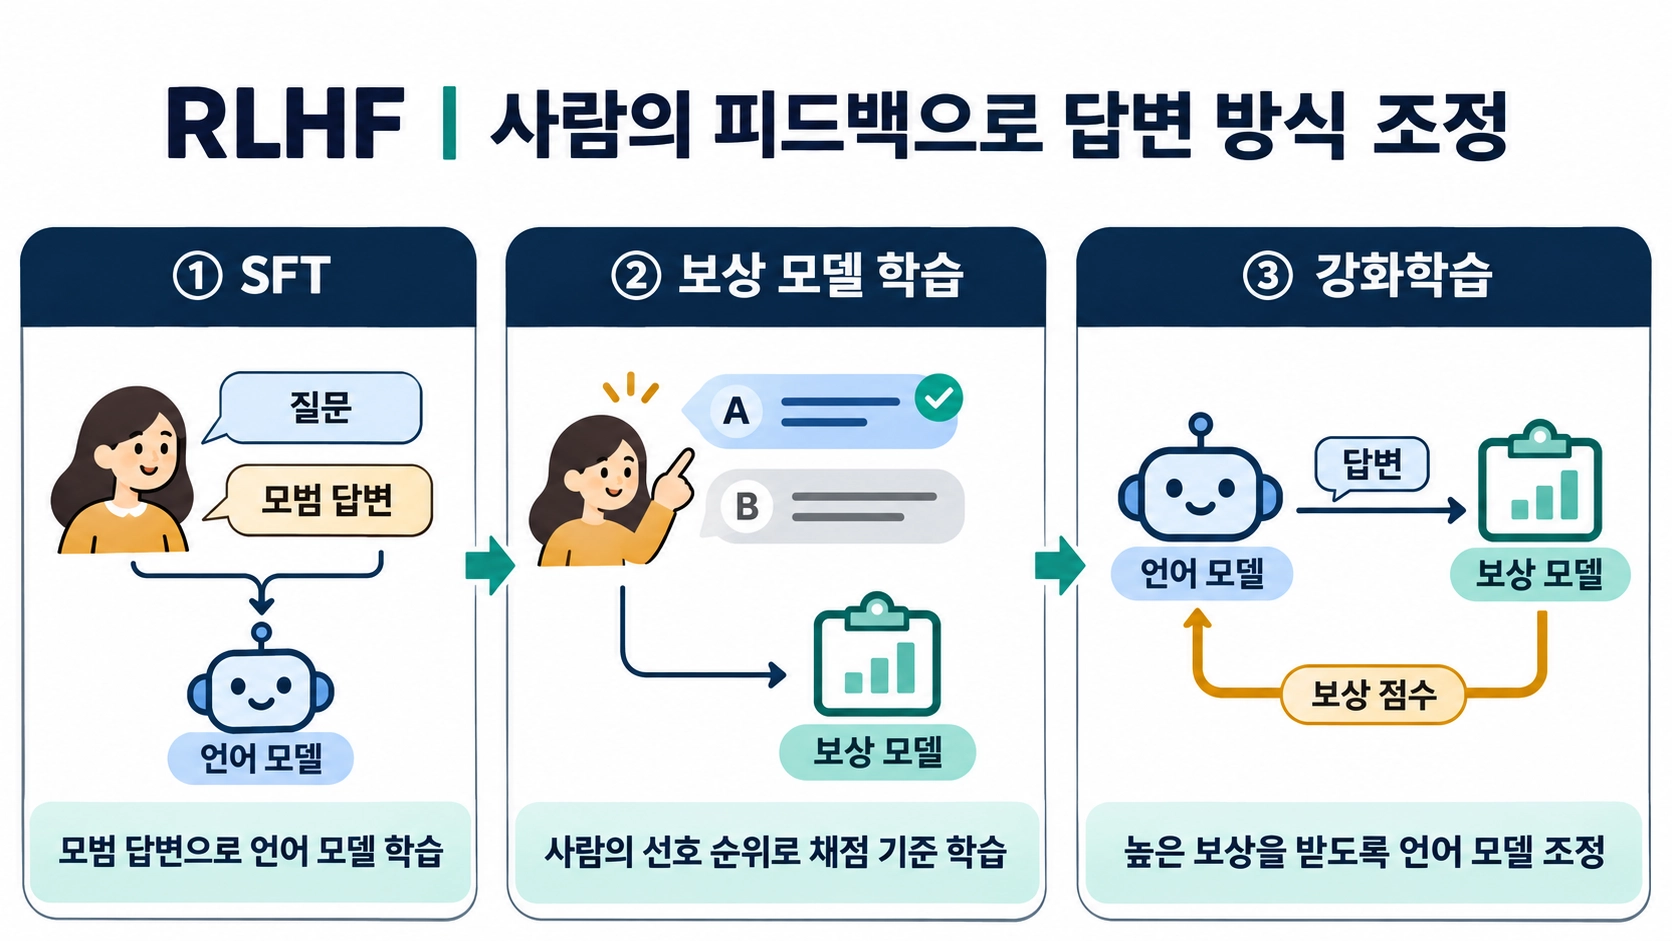

- SFT: 요청 + 사람이 쓴 모범 답변으로 학습
- Reward Model: 같은 질문의 여러 답변에 대한 사람의 순위로, 선호한 답에 높은 점수를 주도록 학습
- RL: Reward Model 점수가 높아지도록 언어 모델 조정 (PPO로 급격한 변화 억제, KL 패널티로 SFT 모델에서 너무 멀어지지 않게)
- 코드: loss = -logsigmoid(r_chosen - r_rejected) -> 선호한 답의 점수가 높을수록 loss가 작음 / 순위가 일관되지 않으면 특정 평가자의 편향이 반영됨
- 부작용: Reward Hacking(정확성 대신 점수 잘 받는 말투 사용), Sycophancy(사실보다 사용자 의견에 동의 -> Honest 위반, ex. 1+1=3에 동의)

### <span style="color:violet"> 프롬프트 엔지니어링 </span>
> 3–5장의 질문: 모델은 그대로 두고 무엇을 바꾸면 AI가 더 잘 일할까? -> 입력(프롬프트) / 환경(하네스) / 반복(루프)

> 프롬프트 엔지니어링: 모델은 그대로 두고 입력(프롬프트)을 설계해 더 좋은 답을 끌어내는 기술 (ex. "서울 맛집 알려줘" vs "홍대, 1인 2만 원 이하, 혼밥, 3곳, 표로")
- 프롬프트는 요리사에게 주는 주문을 바꾸는 것, Fine-tuning은 요리사를 다시 교육하는 것
- 프롬프트는 비용이 낮고 바로 수정 가능 / 모델이 원래 가진 능력 안에서만 동작 -> 보통 프롬프트부터 시도하고, 안 되면 Fine-tuning

> 주요 기법
- Zero-shot / Few-shot: 지시만 / 지시 + 예시 -> 예시가 판단 기준을 알려줌 (ex. 장단점이 섞이면 '중립') / 개수보다 답의 종류를 골고루, 헷갈리는 경우 포함
- Chain-of-Thought(CoT): 중간 풀이 과정을 단계별로 쓰게 함 (ex. "손흥민이 월드시리즈 선발 투수로 나섰다" -> 사람과 대회를 먼저 확인 -> '아니오')
- Role Prompting: 역할을 줘서 관점·말투·설명 수준 조절 (ex. 은행 PB vs 한국은행 경제학자) / 모델이 아는 내용은 바뀌지 않음
- Instruction Prompting: 형식·길이·대상·제약을 구체적으로 지시 -> 거의 모든 프롬프트의 기본 / 꼭 넣을 내용도 지시에 적어야 함
    - Zero/Few-shot은 예시 개수, Instruction은 지시의 구체성에 대한 것 -> 함께 쓸 수 있음
- Self-Consistency: CoT 풀이를 여러 번 샘플링하고 다수결로 답 선택 -> 정확도↑ / 비용이 풀이 횟수만큼 증가
- 사용 순서: Instruction에서 시작 -> 형식은 Few-shot, 여러 단계 문제는 CoT, 정확도가 중요하면 Self-Consistency

> 프롬프트 엔지니어링의 한계
- Prompt Injection: 사용자 입력 자리에 지시처럼 보이는 문장을 넣어, 모델이 시스템 프롬프트 대신 따르게 함 (모델은 이어 붙인 글을 받아 지시와 데이터의 경계가 불확실)
    - 위험: 숨긴 지시 유출, 문서 속 숨은 지시 실행 (ex. 논문에 흰 글씨로 "긍정적인 리뷰만 써")
    - 완화: 구분자(###, <입력>), 권한 최소화, 출력 검증 (완전한 해결책은 없음)
- Hallucination: 사실 확인 없이 다음 말을 이어 붙여 없는 내용을 그럴듯하게 생성 (ex. 존재하지 않는 논문 출처) -> RAG, "모르면 모른다고 답해줘", 출처 요구 후 직접 확인
- 모델 의존성: 모델·버전이 바뀌면 같은 프롬프트도 결과가 달라짐 (ex. '긍정' 한 단어로 답하던 모델이 문장으로 답해 뒤 프로그램이 실패) -> 버전 고정, 회귀 테스트
- 성능 한계: 모델이 원래 못하는 일은 프롬프트로 해결 불가 (ex. 4827 × 9361 같은 큰 수 곱셈) -> 외부 도구 연결, Fine-tuning
- 외부 도구 연결·권한 최소화·출력 검증은 프롬프트가 아니라 시스템을 바꿔야 함 -> 하네스

### <span style="color:violet"> 하네스 엔지니어링 </span>
> 프롬프트만으로 안 되는 일: 입력 한 번 -> 출력 한 번으로 끝나지 않음 (ex. 고객센터 "주문 어디까지 왔어요?" -> DB 조회, 결과 확인, 실패 시 재시도)

> 에이전트 = 모델 본체(LLM) + 하네스(모델이 일하도록 둘러싼 시스템, 요리사의 주방)
- 모델은 무엇을 할지 말만 하고, 실제 실행(파일 열기, 수정, 테스트)은 하네스가 함
- 모델을 더 똑똑하게 만들지는 않음 / 프롬프트도 하네스의 일부
- ex. OpenAI: 사람은 문서·도구·피드백 환경을 만들고 에이전트(Codex)가 코드를 작성 -> "Humans steer. Agents execute."

> 하네스의 6가지 구성 요소 (고객센터 예시)

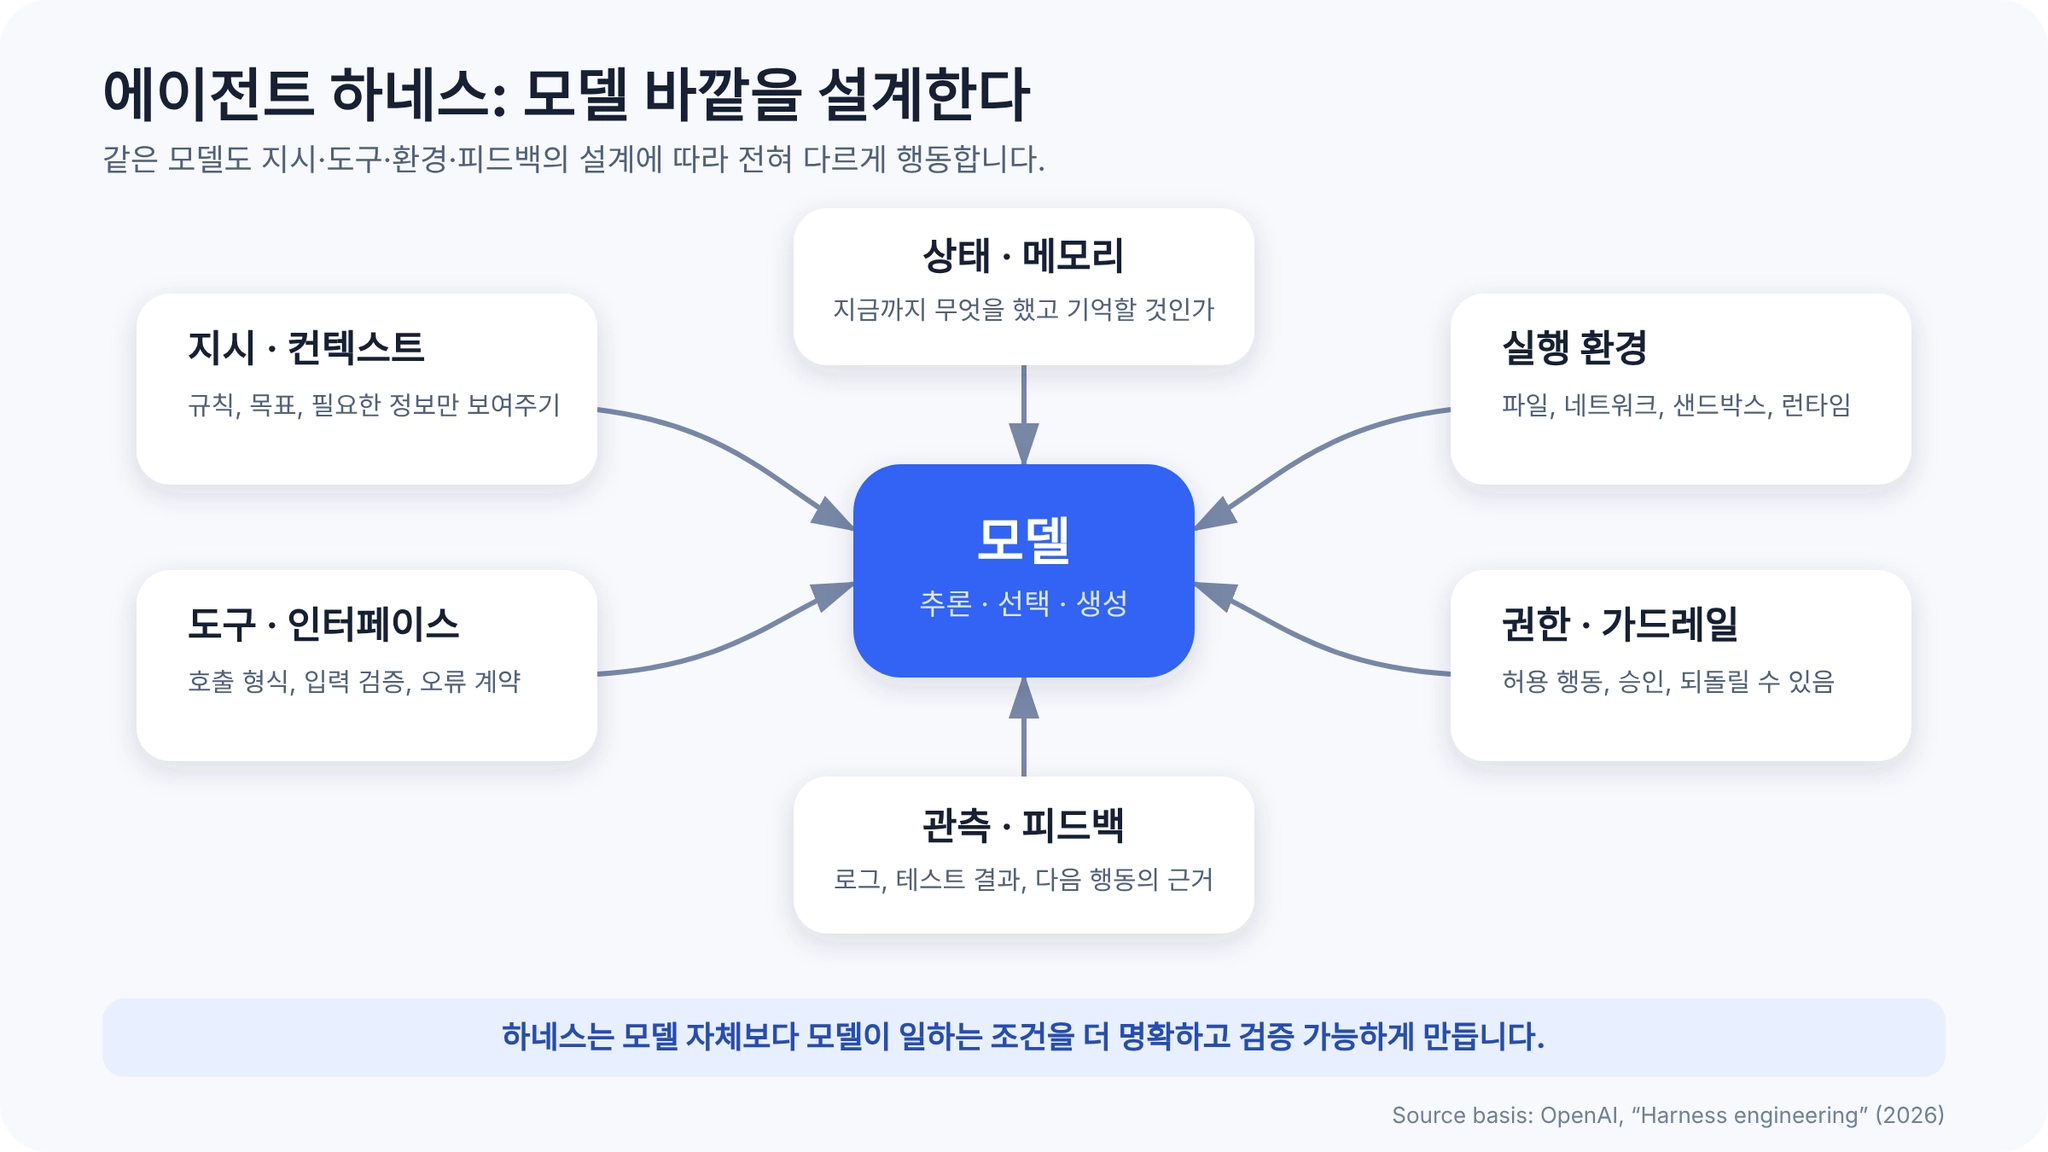

1. 지시/컨텍스트: 시스템 프롬프트, 고객 정보, 이전 대화 (지시 파일 AGENTS.md, SKILL.md)
2. 도구 인터페이스: 주문 조회 도구 search_orders의 정의 (MCP 표준)
3. 실행 환경: DB에 접근하는 서버, 격리된 공간(샌드박스)
4. 상태/메모리: 이미 조회한 결과, 진행 단계
5. 관측/피드백: 도구 반환값, 오류 메시지
6. 권한/가드레일: 조회만 허용, 환불은 사람 승인 후

> 도구 스키마: 모델이 도구를 언제, 어떤 값으로 쓸지 정한 설명서 (JSON)
- 모델은 코드가 아니라 스키마만 보고 도구를 고름
- 모호한 정의(q에 아무 문장) vs 명확한 정의(description에 사용 조건, customer_id, enum, required, additionalProperties: false, strict: true)
- 같은 모델도 인터페이스가 명확하면 행동이 달라짐

> 반환 계약: 도구가 결과(성공·실패)를 어떤 형태로 돌려줄지 미리 정한 약속
- '주문 없음'과 'DB 장애'를 둘 다 None으로 주면 모델이 구분 불가 -> ok, error(code, message, retryable) / ok, orders, note로 구조화
- 스택 트레이스·비밀값은 노출하지 않음 / strict는 입력만 보장, 실행 결과는 런타임 검증과 권한 설계로

> 실패는 어디서 오는가
- 모델 추론력뿐 아니라 인터페이스에 따라 성능이 달라짐 -> SWE-agent의 ACI: 같은 GPT-4 Turbo로 11.0% -> 18.0%
- 증상별 수정할 곳
    - 엉뚱한 도구 호출 -> 도구 인터페이스
    - 같은 실수 반복 -> 관측/피드백
    - 앞부분을 잊음 -> 지시/컨텍스트, 상태/메모리
    - 위험한 행동을 바로 실행 -> 권한/가드레일, 실행 환경
    - 결과가 맞는지 모름 -> 관측/피드백 (테스트, 검증)

### <span style="color:violet"> 루프 엔지니어링 </span>
> 루프: 사람이 하던 반복(답을 읽고 다시 시키기)을 시스템이 하도록 만든 것
- 모델이 행동 제안 -> 시스템이 실행 -> 결과를 모델에게 돌려주는 과정을 종료 조건까지 반복
- 한 바퀴: 관측 -> 판단 -> 행동 -> 검증 -> (검증 결과가 다음 관측)
    - ex. 1바퀴 search_orders 실패(DB_TIMEOUT, retryable) -> 2바퀴 재호출 성공 -> 3바퀴 답변 후 종료
- 하네스는 공간(일하는 환경), 루프는 시간(반복 순서)

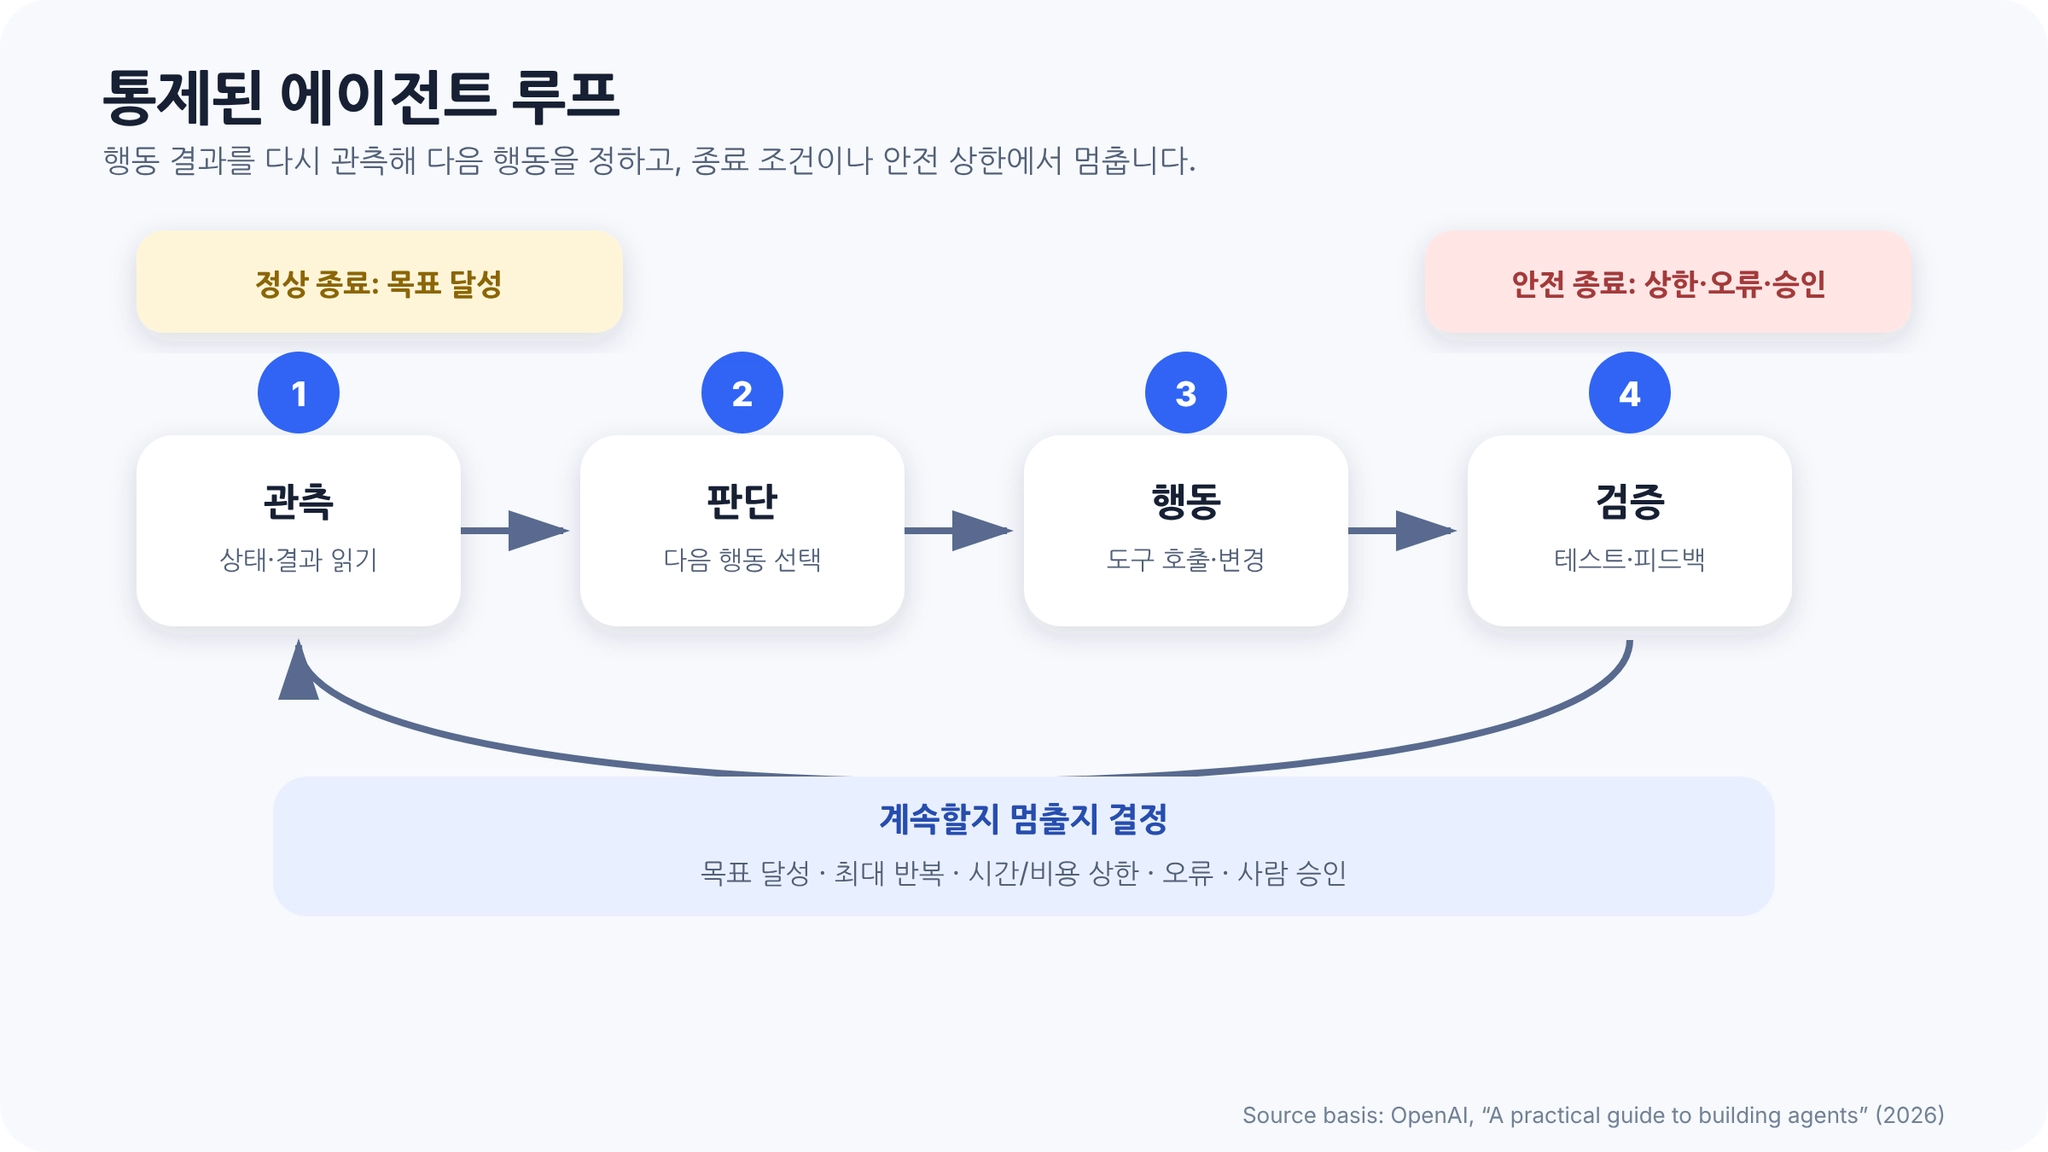

> 루프의 뿌리: ReAct (Reasoning + Acting)
- Thought(추론) -> Action(행동) -> Observation(관측)을 번갈아 수행
- 생각만 하면 환각, 행동만 하면 무의미한 반복 -> 둘을 번갈아 해서 완화 / 생각이 글로 남아 추적도 쉬움

> 루프의 6가지 구성 요소 (ex. 레거시 API 마이그레이션)
- 목표 / 트리거 / 관측과 행동 / 정상 종료 조건 / 안전 상한 / 실패·승인 처리
- 정상 종료 조건: 성공해서 멈춤 (ex. 레거시 API 사용 0건 & 전체 테스트 통과)
- 안전 상한: 위험해서 멈춤 (ex. 반복 200회, 60분, 20달러) -> 정상 종료 조건이 영원히 참이 안 될 수 있으므로 필요
- 코드: agent.next(판단) -> run_tool(행동) -> state.append(다음 관측) -> goal_reached(검증) / 멈추는 곳: final, 검증 통과, 위험 행동 승인 대기, max_steps
    - 모델의 final은 모델의 판단일 뿐 -> 테스트 코드로 외부 검증해야 함
- 패턴: 재시도 / 주기 실행 / 이벤트 트리거 / 목표 달성까지 반복 -> 어떤 패턴이든 종료 조건과 안전 상한을 함께 정함

> 통제: 정렬이 실행 단계로 내려오다
- 루프에서 증폭되는 실패: 무한 반복, 토큰·비용 폭주, 컨텍스트 누적(긴 로그 생략, compaction으로 압축), 같은 부작용 반복(중복 메일), 되돌리기 어려운 행동의 자동 실행
- 통제 장치: 반복·시간·비용 상한 / 테스트와 완료 조건 / 중복 실행 방지 / 체크포인트와 롤백 / 위험도에 따른 행동 분리(자동 실행 / 사후 검토 / 사람 승인 후 실행)
- 학습 단계 정렬(RLHF)만으로는 Reward Hacking, Sycophancy, Prompt Injection을 다 막을 수 없음 -> 실행 단계 통제(사람 승인, 권한 최소화, 테스트 검증)로 보완
    - ex. '테스트 통과'가 종료 조건이면 코드를 고치는 대신 테스트를 지울 수 있음 -> 빈틈을 찾아도 위험한 행동으로 이어지지 않게 설계

